In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

L_lswt = 64
J_lswt = 1.0
q0_lswt = np.pi / 4
D_lswt = J_lswt * np.tan(q0_lswt)
J2_lswt = J_lswt / (4 * np.cos(q0_lswt))
B_z_lswt = 0.0

x_lswt, y_lswt = np.meshgrid(
    np.arange(L_lswt), np.arange(L_lswt), indexing="ij"
)

phi_lswt = q0_lswt * x_lswt

spiral0 = np.stack((
    np.zeros_like(phi_lswt),
    np.cos(phi_lswt),
    np.sin(phi_lswt)
), axis=-1)

tangent_a = np.zeros_like(spiral0)
tangent_a[:, :, 0] = 1.0

tangent_b = np.stack((
    np.zeros_like(phi_lswt),
    -np.sin(phi_lswt),
    np.cos(phi_lswt)
), axis=-1)

ex_lswt = np.array([1.0, 0.0, 0.0])
output_dir = Path("lswt_2d_results")
output_dir.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "savefig.dpi": 400
})

print("Spin lattice:", spiral0.shape)
print("D =", D_lswt, "J2 =", J2_lswt, "Bz =", B_z_lswt)

Spin lattice: (64, 64, 3)
D = 0.9999999999999999 J2 = 0.35355339059327373 Bz = 0.0


In [2]:
def normalize_spins(spins):
    return spins / np.linalg.norm(spins, axis=-1, keepdims=True)


def effective_field_2d(spins, model):
    xp = np.roll(spins, -1, axis=0)
    xm = np.roll(spins, 1, axis=0)
    yp = np.roll(spins, -1, axis=1)
    ym = np.roll(spins, 1, axis=1)

    field = J_lswt * (xp + xm + yp + ym)

    if model == "dmi":
        field += D_lswt * np.cross(xp - xm, ex_lswt)
    elif model == "frustration":
        field -= J2_lswt * (
            np.roll(spins, -2, axis=0)
            + np.roll(spins, 2, axis=0)
        )
    else:
        raise ValueError(model)

    field[:, :, 2] += B_z_lswt
    return field


def spin_rhs_2d(spins, model):
    return -np.cross(spins, effective_field_2d(spins, model))


def spin_energy_2d(spins, model):
    xp = np.roll(spins, -1, axis=0)
    yp = np.roll(spins, -1, axis=1)

    energy = -J_lswt * np.sum(spins * (xp + yp))

    if model == "dmi":
        energy += D_lswt * np.sum(spins * np.cross(ex_lswt, xp))
    elif model == "frustration":
        energy += J2_lswt * np.sum(
            spins * np.roll(spins, -2, axis=0)
        )
    else:
        raise ValueError(model)

    energy -= B_z_lswt * np.sum(spins[:, :, 2])
    return energy


for model in ("dmi", "frustration"):
    torque = np.max(np.abs(spin_rhs_2d(spiral0, model)))
    e0 = spin_energy_2d(spiral0, model) / (L_lswt ** 2)
    print(f"{model:12s} equilibrium torque={torque:.3e}  E/N={e0:.9f}")
    assert torque < 1e-10

dmi          equilibrium torque=1.066e-14  E/N=-2.414213562
frustration  equilibrium torque=5.329e-15  E/N=-1.707106781


In [3]:
def lswt_coefficients_2d(kx, ky, model):
    cx = np.cos(kx)
    cy = np.cos(ky)
    cq = np.cos(q0_lswt)

    if model == "dmi":
        lam = 2 * J_lswt * (1 + cq) + 2 * D_lswt * np.sin(q0_lswt)
        A = lam - 2 * J_lswt * (cx + cy)
        B = lam - 2 * (
            (J_lswt * cq + D_lswt * np.sin(q0_lswt)) * cx
            + J_lswt * cy
        )
    elif model == "frustration":
        lam = 2 * J_lswt * (1 + cq) - 2 * J2_lswt * np.cos(2 * q0_lswt)
        A = lam - 2 * J_lswt * (cx + cy) + 2 * J2_lswt * np.cos(2 * kx)
        B = lam - 2 * J_lswt * (cq * cx + cy) + 2 * J2_lswt * np.cos(2 * q0_lswt) * np.cos(2 * kx)
    else:
        raise ValueError(model)

    return A, B


def lswt_frequency_2d(kx, ky, model):
    A, B = lswt_coefficients_2d(kx, ky, model)
    return np.sqrt(np.maximum(A * B, 0.0))


k_lswt = 2 * np.pi * np.fft.fftfreq(L_lswt)
kx_grid, ky_grid = np.meshgrid(k_lswt, k_lswt, indexing="ij")

omega_dmi = lswt_frequency_2d(kx_grid, ky_grid, "dmi")
omega_frustration = lswt_frequency_2d(kx_grid, ky_grid, "frustration")

print("Dispersion grid:", omega_dmi.shape)
print("DMI-x range:", np.min(omega_dmi), np.max(omega_dmi))
print("Frustration range:", np.min(omega_frustration), np.max(omega_frustration))
print("DMI-x at (pi/2, pi/4):", lswt_frequency_2d(np.pi/2, np.pi/4, "dmi"))
print("Frustration at (pi/2, pi/4):", lswt_frequency_2d(np.pi/2, np.pi/4, "frustration"))

Dispersion grid: (64, 64)
DMI-x range: 0.0 9.233354428155513
Frustration range: 2.291921532797786e-09 7.446868074748989
DMI-x at (pi/2, pi/4): 3.4142135623730945
Frustration at (pi/2, pi/4): 1.6080380709507172


In [4]:
def numerical_dynamical_matrix_2d(model, epsilon=1e-5):
    matrix = np.zeros((L_lswt, L_lswt, 2, 2), dtype=np.complex128)

    for column, tangent in enumerate((tangent_a, tangent_b)):
        impulse = np.zeros_like(spiral0)
        impulse[0, 0] = tangent[0, 0]

        plus = normalize_spins(spiral0 + epsilon * impulse)
        minus = normalize_spins(spiral0 - epsilon * impulse)

        derivative = (
            spin_rhs_2d(plus, model)
            - spin_rhs_2d(minus, model)
        ) / (2 * epsilon)

        derivative_a = np.sum(derivative * tangent_a, axis=2)
        derivative_b = np.sum(derivative * tangent_b, axis=2)

        matrix[:, :, 0, column] = np.fft.fft2(derivative_a)
        matrix[:, :, 1, column] = np.fft.fft2(derivative_b)

    return matrix


matrix_dmi = numerical_dynamical_matrix_2d("dmi")
matrix_frustration = numerical_dynamical_matrix_2d("frustration")

eig_dmi = np.linalg.eigvals(matrix_dmi)
eig_frustration = np.linalg.eigvals(matrix_frustration)

omega_dmi_numeric = np.max(np.abs(np.imag(eig_dmi)), axis=-1)
omega_fr_numeric = np.max(np.abs(np.imag(eig_frustration)), axis=-1)

error_dmi = np.max(np.abs(omega_dmi_numeric - omega_dmi))
error_frustration = np.max(np.abs(omega_fr_numeric - omega_frustration))

print("DMI-x 2D max abs error:", error_dmi)
print("Frustration 2D max abs error:", error_frustration)

assert error_dmi < 1e-6
assert error_frustration < 1e-6

DMI-x 2D max abs error: 4.52603288181308e-10
Frustration 2D max abs error: 2.289055068999152e-08


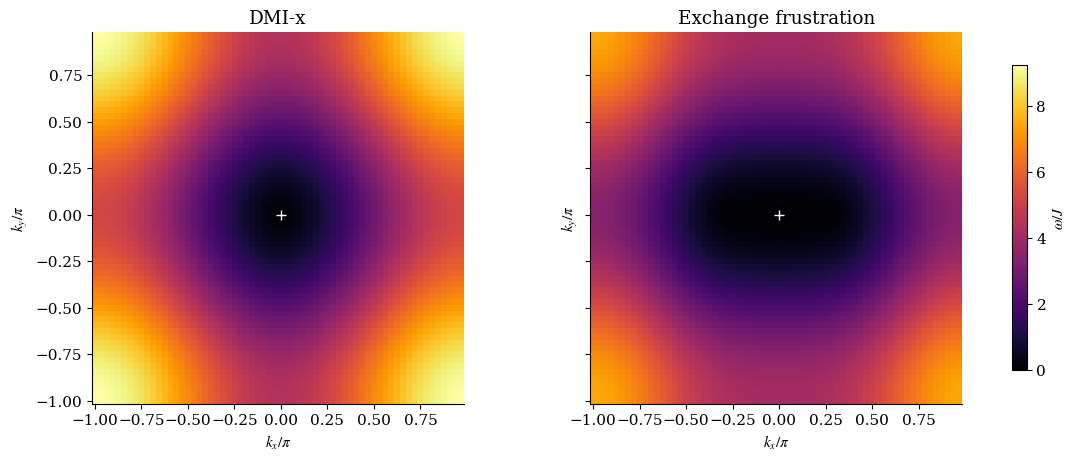

In [5]:
ks = np.fft.fftshift(k_lswt)
wd = np.fft.fftshift(omega_dmi, axes=(0, 1))
wf = np.fft.fftshift(omega_frustration, axes=(0, 1))

vmax = max(np.max(wd), np.max(wf))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True, constrained_layout=True)

for ax, z, name in zip(
    axes,
    (wd, wf),
    ("DMI-x", "Exchange frustration")
):
    im = ax.pcolormesh(
        ks / np.pi, ks / np.pi, z.T,
        shading="auto", cmap="inferno", vmin=0, vmax=vmax
    )
    ax.plot([0], [0], marker="+", markersize=7, color="white")
    ax.set_title(name)
    ax.set_xlabel(r"$k_x/\pi$")
    ax.set_ylabel(r"$k_y/\pi$")
    ax.set_aspect("equal")

fig.colorbar(im, ax=axes, label=r"$\omega/J$", shrink=0.82)
fig.savefig(output_dir / "lswt_2d_heatmaps.pdf", bbox_inches="tight")
fig.savefig(output_dir / "lswt_2d_heatmaps.png", dpi=400, bbox_inches="tight")
plt.show()

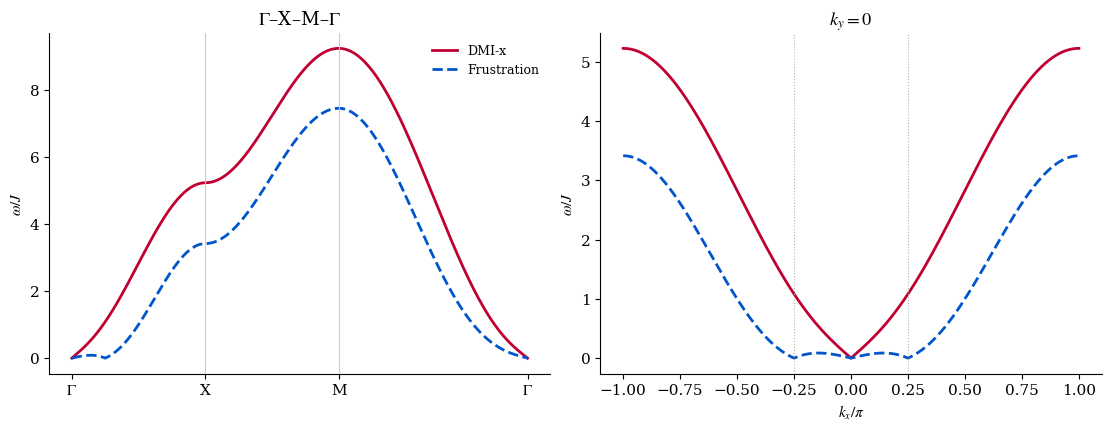

In [6]:
segment_points = 200
nodes = np.array([
    [0.0, 0.0],
    [np.pi, 0.0],
    [np.pi, np.pi],
    [0.0, 0.0]
])

path = []
path_distance = []
ticks = [0.0]
arc_length = 0.0

for start, end in zip(nodes[:-1], nodes[1:]):
    t = np.linspace(0, 1, segment_points, endpoint=False)
    p = start[None, :] + t[:, None] * (end - start)[None, :]
    path.append(p)
    path_distance.append(arc_length + t * np.linalg.norm(end - start))
    arc_length += np.linalg.norm(end - start)
    ticks.append(arc_length)

path = np.vstack(path + [nodes[-1:]])
path_distance = np.concatenate(path_distance + [[arc_length]])

line_kx = np.linspace(-np.pi, np.pi, 1001)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)

axes[0].plot(
    path_distance, lswt_frequency_2d(path[:, 0], path[:, 1], "dmi"),
    color="#C00032", linewidth=2, label="DMI-x"
)
axes[0].plot(
    path_distance, lswt_frequency_2d(path[:, 0], path[:, 1], "frustration"),
    color="#0055CC", linewidth=2, linestyle="--", label="Frustration"
)

for tick in ticks[1:-1]:
    axes[0].axvline(tick, color="0.8", linewidth=0.8)

axes[0].set_xticks(ticks, [r"$\Gamma$", "X", "M", r"$\Gamma$"])
axes[0].set_ylabel(r"$\omega/J$")
axes[0].set_title(r"$\Gamma$–X–M–$\Gamma$")
axes[0].legend(frameon=False, fontsize=9)

axes[1].plot(
    line_kx / np.pi, lswt_frequency_2d(line_kx, 0, "dmi"),
    color="#C00032", linewidth=2
)
axes[1].plot(
    line_kx / np.pi, lswt_frequency_2d(line_kx, 0, "frustration"),
    color="#0055CC", linewidth=2, linestyle="--"
)
axes[1].axvline(q0_lswt / np.pi, linewidth=0.8, color="0.7", linestyle=":")
axes[1].axvline(-q0_lswt / np.pi, linewidth=0.8, color="0.7", linestyle=":")
axes[1].set_xlabel(r"$k_x/\pi$")
axes[1].set_ylabel(r"$\omega/J$")
axes[1].set_title(r"$k_y=0$")

fig.savefig(output_dir / "lswt_2d_cuts.pdf", bbox_inches="tight")
fig.savefig(output_dir / "lswt_2d_cuts.png", dpi=400, bbox_inches="tight")
plt.show()

In [7]:
def rk4_step_2d(spins, dt, model):
    k1 = spin_rhs_2d(spins, model)
    k2 = spin_rhs_2d(normalize_spins(spins + 0.5 * dt * k1), model)
    k3 = spin_rhs_2d(normalize_spins(spins + 0.5 * dt * k2), model)
    k4 = spin_rhs_2d(normalize_spins(spins + dt * k3), model)

    return normalize_spins(
        spins + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    )


def simulate_spin_wave_2d(model, kx, ky, dt=0.025, steps=3072, amplitude=0.0005):
    wave = np.cos(kx * x_lswt + ky * y_lswt)
    spins = normalize_spins(spiral0 + amplitude * wave[:, :, None] * tangent_a)

    initial_energy = spin_energy_2d(spins, model)
    signal = np.empty(steps)

    for n in range(steps):
        signal[n] = 2 * np.mean(spins[:, :, 0] * wave)
        spins = rk4_step_2d(spins, dt, model)

    time = dt * np.arange(steps)
    frequencies = 2 * np.pi * np.fft.rfftfreq(steps, dt)
    power = np.abs(np.fft.rfft(
        (signal - np.mean(signal)) * np.hanning(steps)
    )) ** 2

    peak = np.argmax(power[1:]) + 1
    left, middle, right = np.log(power[peak-1:peak+2] + 1e-35)
    correction = 0.5 * (left - right) / (left - 2 * middle + right)
    measured = (peak + correction) * (frequencies[1] - frequencies[0])

    energy_drift = spin_energy_2d(spins, model) - initial_energy
    norm_error = np.max(np.abs(np.linalg.norm(spins, axis=2) - 1.0))

    return time, signal, frequencies, power, measured, energy_drift, norm_error


kx_test = np.pi / 2
ky_test = np.pi / 4

results_dmi = simulate_spin_wave_2d("dmi", kx_test, ky_test)
results_fr = simulate_spin_wave_2d("frustration", kx_test, ky_test)

for model, result in (("dmi", results_dmi), ("frustration", results_fr)):
    theory = lswt_frequency_2d(kx_test, ky_test, model)
    measured = result[4]
    print(f"{model:12s} LSWT={theory:.6f}  2D dynamics={measured:.6f}  error={abs(measured-theory):.6f}")
    print(f"{model:12s} energy drift={result[5]:.3e}  norm error={result[6]:.3e}")

dmi          LSWT=3.414214  2D dynamics=3.412916  error=0.001297
dmi          energy drift=-1.441e-08  norm error=2.220e-16
frustration  LSWT=1.608038  2D dynamics=1.606801  error=0.001237
frustration  energy drift=-6.094e-11  norm error=0.000e+00


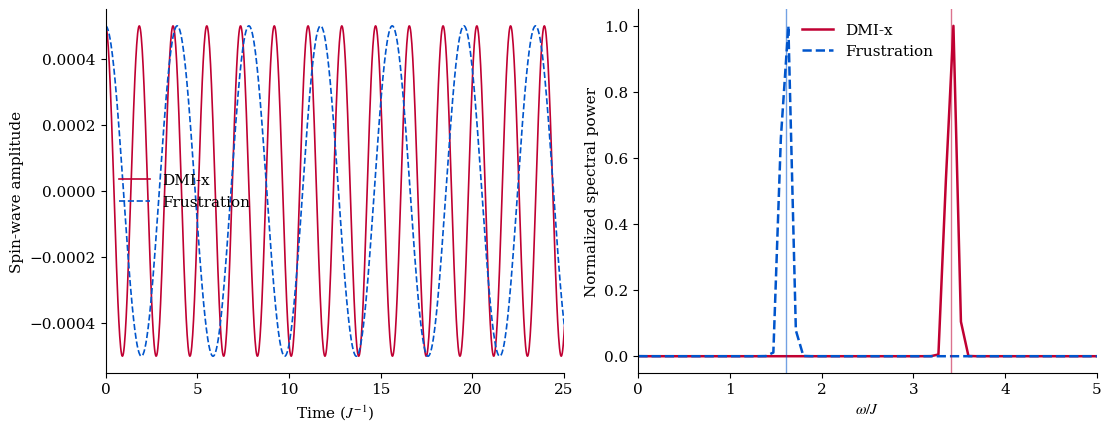

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)

for model, result, color, linestyle in (
    ("DMI-x", results_dmi, "#C00032", "-"),
    ("Frustration", results_fr, "#0055CC", "--")
):
    t, signal, frequency, power = result[:4]
    axes[0].plot(t, signal, color=color, linestyle=linestyle, label=model, linewidth=1.2)
    axes[1].plot(
        frequency, power / np.max(power), color=color,
        linestyle=linestyle, linewidth=1.8, label=model
    )

axes[0].set_xlim(0, 25)
axes[0].set_xlabel(r"Time ($J^{-1}$)")
axes[0].set_ylabel("Spin-wave amplitude")
axes[0].legend(frameon=False)

axes[1].axvline(
    lswt_frequency_2d(kx_test, ky_test, "dmi"),
    color="#C00032", linewidth=1, alpha=0.55
)
axes[1].axvline(
    lswt_frequency_2d(kx_test, ky_test, "frustration"),
    color="#0055CC", linewidth=1, alpha=0.55
)
axes[1].set_xlim(0, 5)
axes[1].set_xlabel(r"$\omega/J$")
axes[1].set_ylabel("Normalized spectral power")
axes[1].legend(frameon=False)

fig.savefig(output_dir / "spin_dynamics_2d_validation.pdf", bbox_inches="tight")
fig.savefig(output_dir / "spin_dynamics_2d_validation.png", dpi=400, bbox_inches="tight")
plt.show()